# Splitting the unrotated merge into three units

A first step toward hybrid surgery with unrotated patches. In the rotated merge
the seam qubits and the generators lie on different diagonals, so a straight
line separates the generators on either side of the seam. In the unrotated
merge they share columns, so the seam column becomes a unit of its own:
`seam_column_interface(x_seam)` sends `x < x_seam` left, `x == x_seam` to the
seam and `x > x_seam` right, and `Surgery.split_seam` splits every generator
whose legs reach another unit.

- **Joint-type layers** (Z for a ZZ merge): the ancillas sit *on* the seam
  column. Each one has legs left, right and along the seam, so it splits into
  three: a left-boundary piece, a seam piece and a right-boundary piece.
- **Other layers**: the seam column has no ancillas; the ancillas in line with
  the boundary columns each touch one seam qubit, so each splits once, giving
  the seam a piece.

The last sections choose the seam unit's region, clusterise it, and realise
the result.

In [19]:
%matplotlib widget
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np

from dizx.builders import surgery_layers
from dizx.surgery import seam_column_interface, two_patch_surgery
from dizx.zx_diagram import NodeType


def split_merge(d, joint, n_cycles=1):
    s = two_patch_surgery(d, joint, layers=surgery_layers(n_cycles), unrotated=True)
    iface = seam_column_interface(s.seam[0][0])
    return s, iface, s.split_seam(iface)

## The pieces, layer by layer

Each panel is one merge layer seen from above. Data qubits are black, seam
qubits ringed. Each generator piece is coloured by its unit and drawn
nudged toward it from its generator's position (the SED's own positions
offset the halves only slightly); thin lines are its legs to data qubits
and thick grey lines the edges joining the pieces of one generator. Squares
are Z-type stabilisers (X spiders), circles X-type (Z spiders).

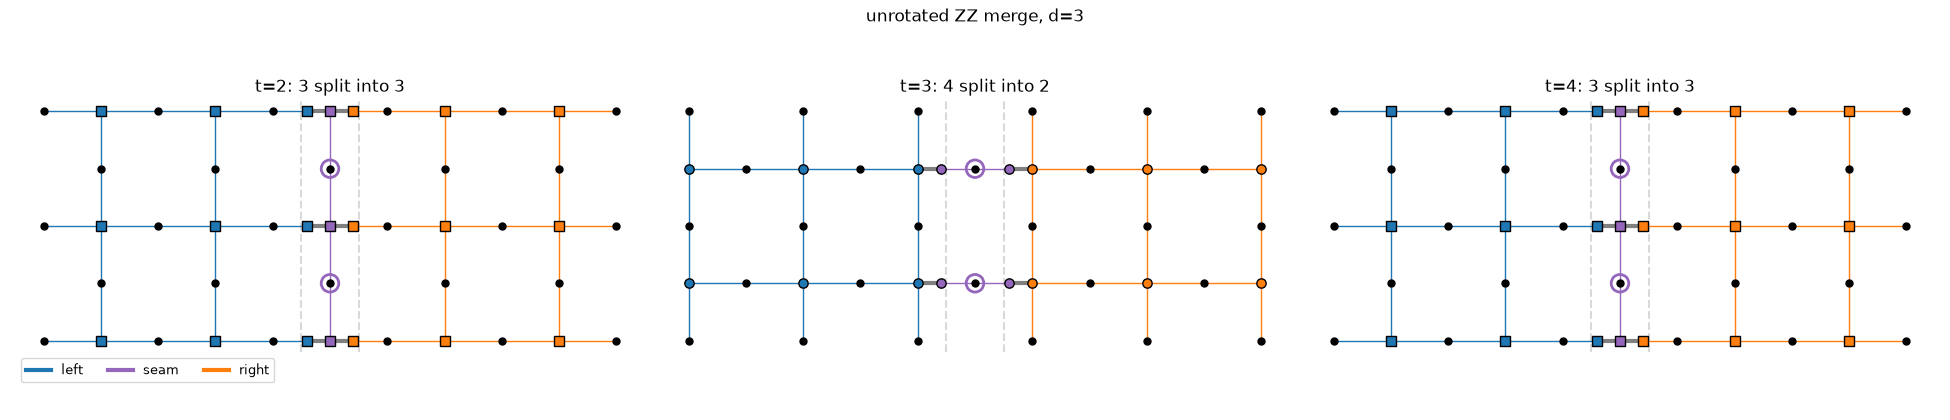

In [20]:
UNIT = {"left": "tab:blue", "seam": "tab:purple", "right": "tab:orange"}
NUDGE = 0.4


def merge_layers(s, sed):
    rounds = set(s.merge_rounds)
    zs = {sed.positions[g][2] for g in sed.types
          if isinstance(g, tuple) and g[0] == "gen" and g[1] in rounds}
    return sorted(zs)


def draw_layer(s, iface, sed, z, ax):
    pos0, x_seam = s.sed.positions, s.seam[0][0]
    centre = {"left": x_seam - 1, "seam": x_seam, "right": x_seam + 1}
    gens = [g for g in s.sed.types if isinstance(g, tuple) and g[0] == "gen" and pos0[g][2] == z]
    pieces = {g: [g] + [v for v in sed.types if isinstance(v, tuple) and v[0] == "split" and v[1] == g]
              for g in gens}
    qx, qy = zip(*s.merged.qubits)
    ax.scatter(qx, qy, c="black", s=25, zorder=3)
    ax.scatter(*zip(*s.seam), facecolor="none", edgecolor="tab:purple", s=160, lw=2, zorder=4)
    for g, group in pieces.items():
        gx, gy = pos0[g][:2]
        at = {}
        for v in group:
            unit = iface(gx, gy) if v == g else v[2]
            dx = 0 if len(group) == 1 else NUDGE * np.sign(centre[unit] - gx)
            at[v] = (gx + dx, gy)
            for u in sed.graph.neighbors(v):
                if isinstance(u, tuple) and u[0] == "data":
                    qx, qy = u[-1]
                    ax.plot([at[v][0], qx], [gy, qy], color=UNIT[unit], lw=1, zorder=1)
            marker = "s" if sed.types[v] is NodeType.X else "o"
            ax.scatter(*at[v], color=UNIT[unit], marker=marker, s=45, edgecolor="black", zorder=5)
        for v in group[1:]:
            ax.plot(*zip(at[g], at[v]), color="0.5", lw=3, zorder=4)
    ax.axvline(x_seam - 0.5, color="0.85", ls="--", zorder=0)
    ax.axvline(x_seam + 0.5, color="0.85", ls="--", zorder=0)
    n = Counter(len(p) for p in pieces.values())
    ax.set_title(f"t={z:g}: " + ", ".join(f"{k} split into {p}" for p, k in sorted(n.items()) if p > 1))
    ax.set_aspect("equal")
    ax.axis("off")


def draw_merge(d, joint, n_cycles=1):
    s, iface, sed = split_merge(d, joint, n_cycles)
    zs = merge_layers(s, sed)
    fig, axes = plt.subplots(1, len(zs), figsize=(6.5 * len(zs), 4.2))
    for ax, z in zip(axes, zs):
        draw_layer(s, iface, sed, z, ax)
    for unit, c in UNIT.items():
        axes[0].plot([], [], color=c, lw=3, label=unit)
    axes[0].legend(loc="upper left", bbox_to_anchor=(0, 0), ncol=3, fontsize=9)
    fig.suptitle(f"unrotated {joint} merge, d={d}")
    fig.tight_layout()
    plt.show()


draw_merge(3, "ZZ")

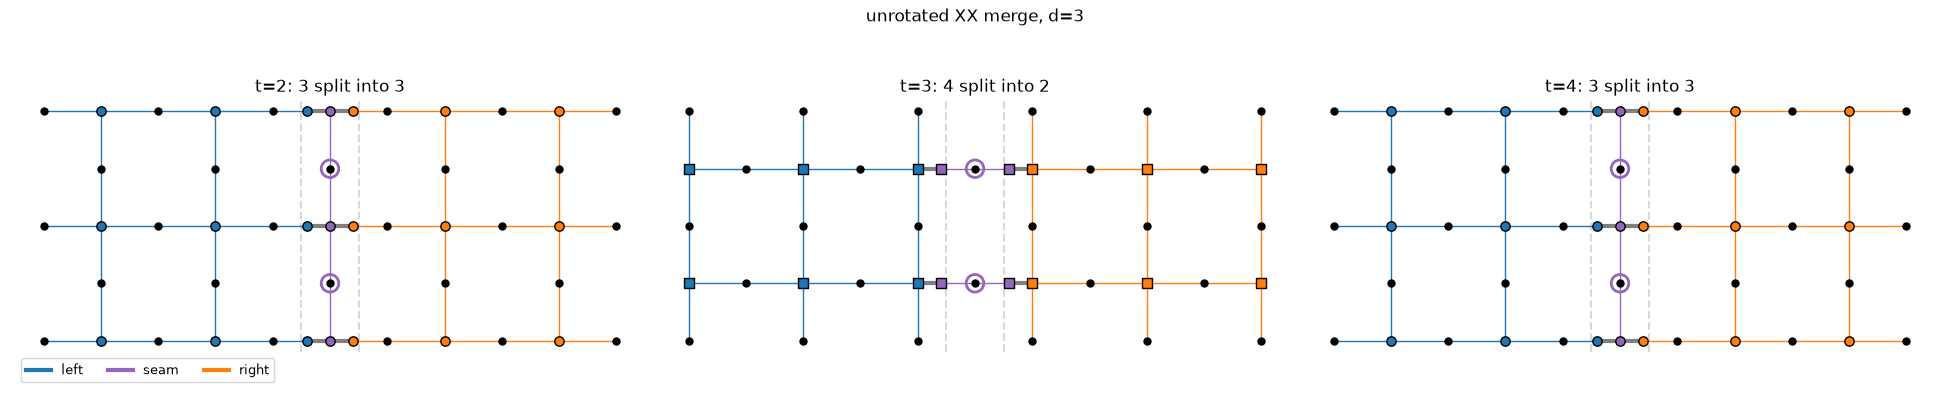

In [21]:
draw_merge(3, "XX")

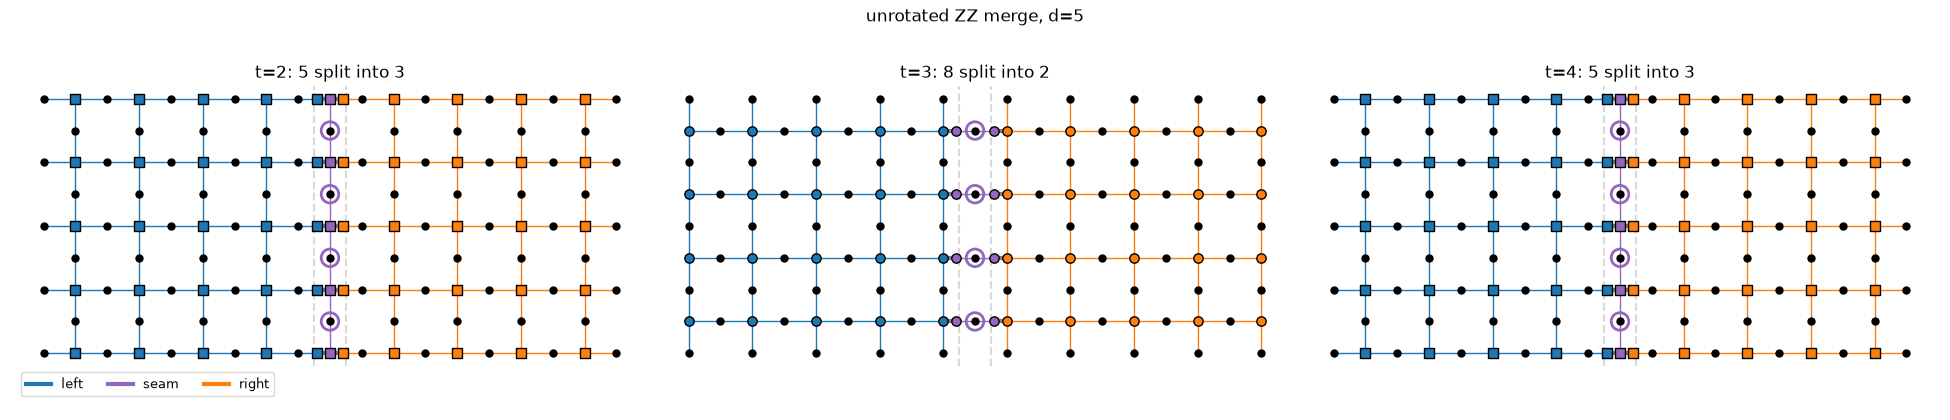

In [22]:
draw_merge(5, "ZZ")

## The SED in 3D

The whole split diagram, and a zoom on the seam columns. The pieces of a
generator sit close together here: the SED offsets each half by half a spacing.

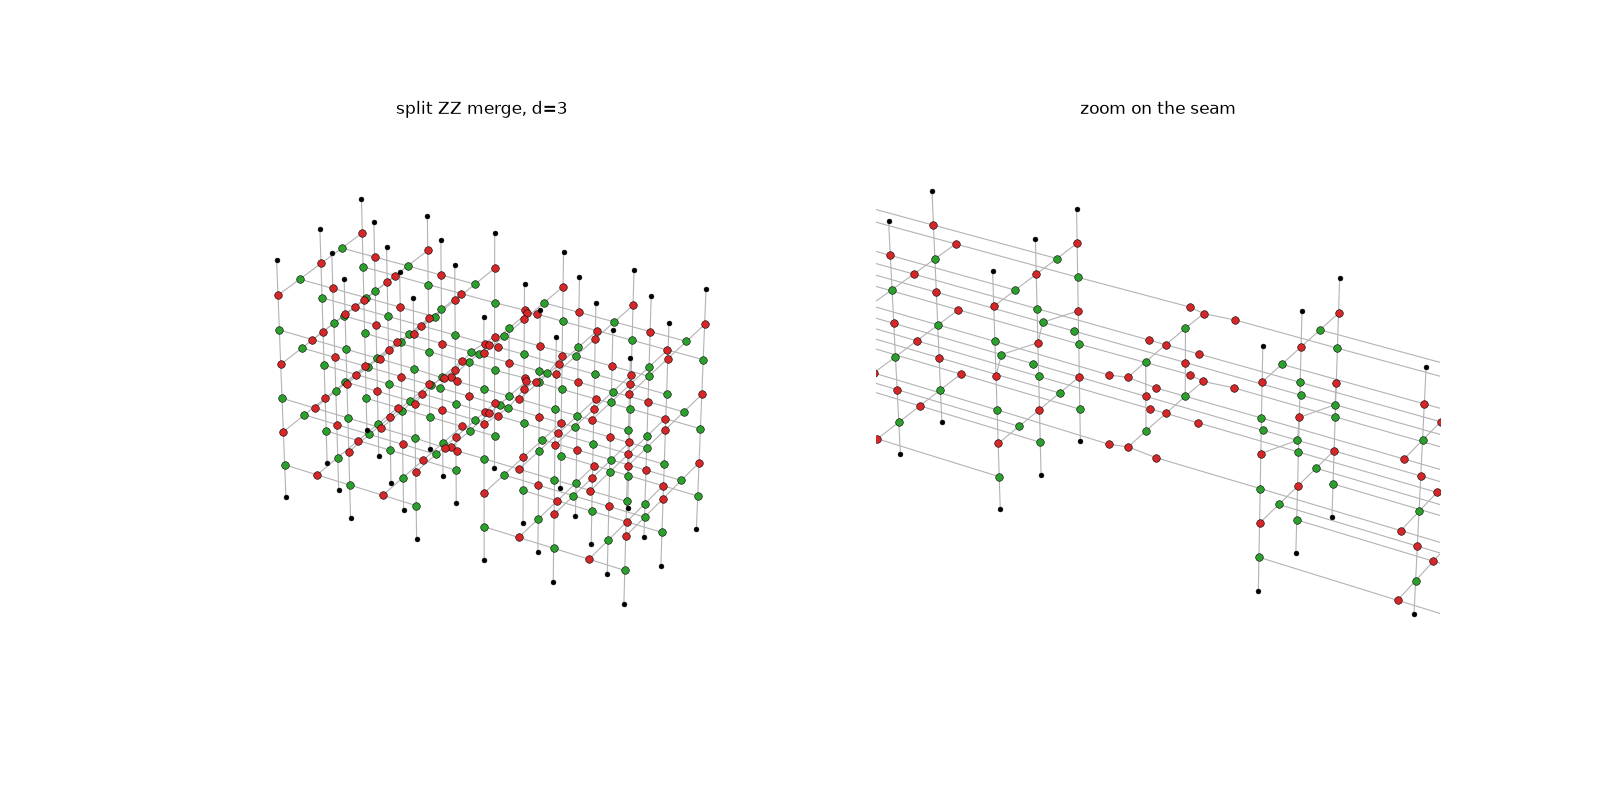

In [23]:
s, iface, sed = split_merge(3, "ZZ")
x_seam = s.seam[0][0]
fig = plt.figure(figsize=(16, 8))
sed.draw(ax=fig.add_subplot(1, 2, 1, projection="3d"), title="split ZZ merge, d=3")
ax = sed.draw(ax=fig.add_subplot(1, 2, 2, projection="3d"), title="zoom on the seam")
ax.set_xlim(x_seam - 1.5, x_seam + 1.5)
plt.show()

## Checks

Every piece touches the qubits of a single unit, the webs and detectors are
still complete, and the counts match d three-way splits per joint-type layer
and 2(d - 1) single splits per other layer.

In [24]:
print(f"{'joint':<6}{'d':>3}{'cycles':>8}{'3-way':>7}{'2-way':>7}{'mixed':>7}  webs/detectors complete")
for joint in ("ZZ", "XX"):
    for d in (3, 5):
        for n_cycles in (1, 2):
            s, iface, sed = split_merge(d, joint, n_cycles)
            pos0 = s.sed.positions
            halves = [v for v in sed.types if isinstance(v, tuple) and v[0] == "split"]
            pieces = Counter(h[1] for h in halves)
            mixed = sum(len({iface(*pos0[u][:2]) for u in sed.graph.neighbors(v)
                             if isinstance(u, tuple) and u[0] == "data"}) > 1
                        for v in halves + list(pieces))
            n = Counter(pieces.values())
            print(f"{joint:<6}{d:>3}{n_cycles:>8}{n[2]:>7}{n[1]:>7}{mixed:>7}  "
                  f"{sed.webs_complete() and sed.detectors_complete()}")

joint   d  cycles  3-way  2-way  mixed  webs/detectors complete
ZZ      3       1      6      4      0  True
ZZ      3       2      9      8      0  True
ZZ      5       1     10      8      0  True
ZZ      5       2     15     16      0  True
XX      3       1      6      4      0  True
XX      3       2      9      8      0  True
XX      5       1     10      8      0  True
XX      5       2     15     16      0  True


## The region for clusterisation

`Surgery.seam_column_region()` returns the split SED, the seam unit's
region (the seam's spiders, every seam piece, and an identity of the *other*
colour on each edge from a three-way generator's seam piece to its boundary
pieces) and the region's boundary fusions.

A resource-state qubit takes part in one fusion, but a three-way seam piece
has two boundary legs. Each leg therefore gets its own leaf: the inserted
identity has the other colour, so after dualising it hangs off the seam piece
by a Hadamard edge (same colour would dualise to a plain edge and collapse
back into the seam piece). The red boundary pieces stay as the local ancillas
(CNOT with their boundary data qubit), and each leaf fuses (a Bell
measurement) directly with its ancilla: `g_seam ┄ id ═ g_L ─ data`. A
once-split generator's seam piece fuses directly with its home ancilla.

`prepare_cluster_region(sed, region, fusions)` dualises the region's X
spiders and leaves the chosen fusion edges unsplit (otherwise `split_boundary`
would give each green–red edge an extra outside copy of the leaf), and
`RealisedSED.hybrid(..., fusions)` realises them: a plain edge as an
`XX`/`ZZ` fusion, an edge through one Hadamard as `XZ`/`ZX`.

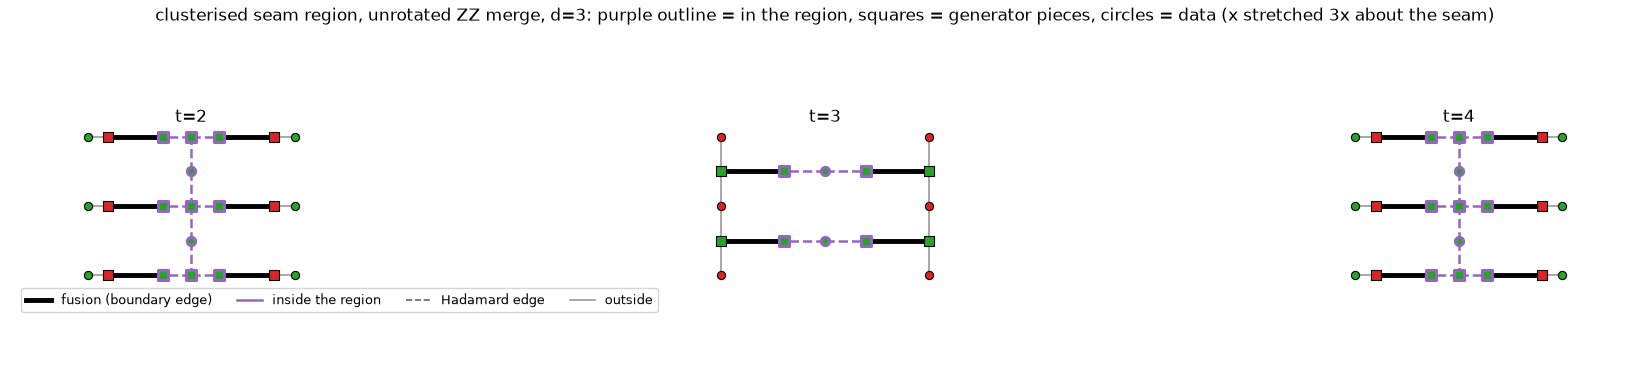

In [25]:
from dizx.transformations import cut_edges, prepare_cluster_region
from dizx.zx_diagram import SPIDERS


def clusterise(d, joint, n_cycles=1):
    s = two_patch_surgery(d, joint, layers=surgery_layers(n_cycles), unrotated=True)
    sed, region, fusions = s.seam_column_region()
    hsed, S = prepare_cluster_region(sed, region, fusions)
    return s, hsed, S, fusions


def schematic(s, hsed):
    """Top-down positions from the node labels: pieces and identities spread
    along their generator's row (the SED's own offsets are tiny)."""
    pos0, x_seam = s.sed.positions, s.seam[0][0]
    centre = {"left": x_seam - 1, "seam": x_seam, "right": x_seam + 1}
    memo = {}

    def at(v):
        if v in memo:
            return memo[v]
        if v[0] == "data":
            p = np.array(v[-1], float)
        elif v[0] == "gen":
            p = np.array(pos0[v][:2], float)
        elif v[0] == "split" and len(v) == 3:           # split_by_side piece
            g = np.array(pos0[v[1]][:2], float)
            reach = 0.8 if pos0[v[1]][0] == x_seam else 0.6
            p = g + [reach * np.sign(centre[v[2]] - g[0]), 0]
        elif v[0] == "id":                               # on the edge (u, w)
            p = at(v[1]) + (at(v[2]) - at(v[1])) / 3
        elif v[0] == "split":                            # split_boundary's outside copy (none here)
            nb = next(u for u in spider_neighbours(v) if u != v[1])
            p = (at(v[1]) + at(nb)) / 2
        else:
            p = np.array(hsed.positions[v][:2], float)
        memo[v] = p
        return p

    def spider_neighbours(v):
        out = []
        for u in hsed.graph.neighbors(v):
            if hsed.types[u] is NodeType.H:
                u = next(w for w in hsed.graph.neighbors(u) if w != v)
            out.append(u)
        return out

    return at, spider_neighbours


SPIDER_COLOUR = {NodeType.Z: "tab:green", NodeType.X: "tab:red"}


STRETCH = 3  # x is stretched about the seam, so the chains along each row separate


def draw_cluster_layer(s, hsed, S, z, ax, half_width=1.6):
    at0, nbrs = schematic(s, hsed)
    x_seam = s.seam[0][0]

    def at(v):
        x, y = at0(v)
        return np.array([x_seam + STRETCH * (x - x_seam), y])

    layer = [v for v, t in hsed.types.items() if t in SPIDERS and v in hsed.positions
             and abs(hsed.positions[v][2] - z) < 0.3 and abs(at0(v)[0] - x_seam) <= half_width]
    keep = set(layer)
    drawn = set()
    for v in layer:
        for u in nbrs(v):
            if u not in keep or frozenset((u, v)) in drawn:
                continue
            drawn.add(frozenset((u, v)))
            had = any(hsed.types[w] is NodeType.H for w in hsed.graph.neighbors(v)
                      if u in hsed.graph.neighbors(w))
            (x0, y0), (x1, y1) = at(v), at(u)
            if (u in S) != (v in S):
                style = dict(color="black", lw=3.5)              # fusion
            elif u in S:
                style = dict(color="tab:purple", lw=1.8, ls="--" if had else "-")
            else:
                style = dict(color="0.6", lw=1.2, ls="--" if had else "-")
            ax.plot([x0, x1], [y0, y1], zorder=1, **style)
    for v in layer:
        x, y = at(v)
        ax.scatter(x, y, s=55 if v[0] != "data" else 35, color=SPIDER_COLOUR[hsed.types[v]],
                   edgecolor="tab:purple" if v in S else "black", lw=2.2 if v in S else 0.8,
                   marker="o" if v[0] == "data" else "s", zorder=3)
    ax.set_xlim(x_seam - STRETCH * half_width - 0.3, x_seam + STRETCH * half_width + 0.3)
    ax.set_aspect("equal")
    ax.set_title(f"t={z:g}")
    ax.axis("off")


def draw_clustered(d, joint, n_cycles=1):
    s, hsed, S, _ = clusterise(d, joint, n_cycles)
    zs = merge_layers(s, s.split_seam(seam_column_interface(s.seam[0][0])))
    fig, axes = plt.subplots(1, len(zs), figsize=(5.5 * len(zs), 0.55 * (2 * d - 2) + 1.6))
    for ax, z in zip(axes, zs):
        draw_cluster_layer(s, hsed, S, z, ax)
    for label, style in (("fusion (boundary edge)", dict(color="black", lw=3.5)),
                         ("inside the region", dict(color="tab:purple", lw=1.8)),
                         ("Hadamard edge", dict(color="0.4", lw=1.2, ls="--")),
                         ("outside", dict(color="0.6", lw=1.2))):
        axes[0].plot([], [], label=label, **style)
    axes[0].legend(loc="upper left", bbox_to_anchor=(0, 0), ncol=4, fontsize=9)
    fig.suptitle(f"clusterised seam region, unrotated {joint} merge, d={d}: purple outline = in the region, "
                 f"squares = generator pieces, circles = data (x stretched {STRETCH}x about the seam)")
    fig.tight_layout()
    plt.show()
    return s, hsed, S


s, hsed, S = draw_clustered(3, "ZZ")

A row of a ZZ merge's Z layer (t=2, 4) reads, left to right,
`data ─ g_L ═ id ┄ g_seam ┄ id ═ g_R ─ data`: the local ancillas `g_L`,
`g_R` (red) fuse (black) with the leaves `id`, and the seam piece `g_seam`,
now green, reaches its leaves and the seam data by Hadamard edges. In the X
layer (t=3) each boundary ancilla fuses with its seam piece. Either way, each
fusion joins a cluster node to an original ancilla piece.

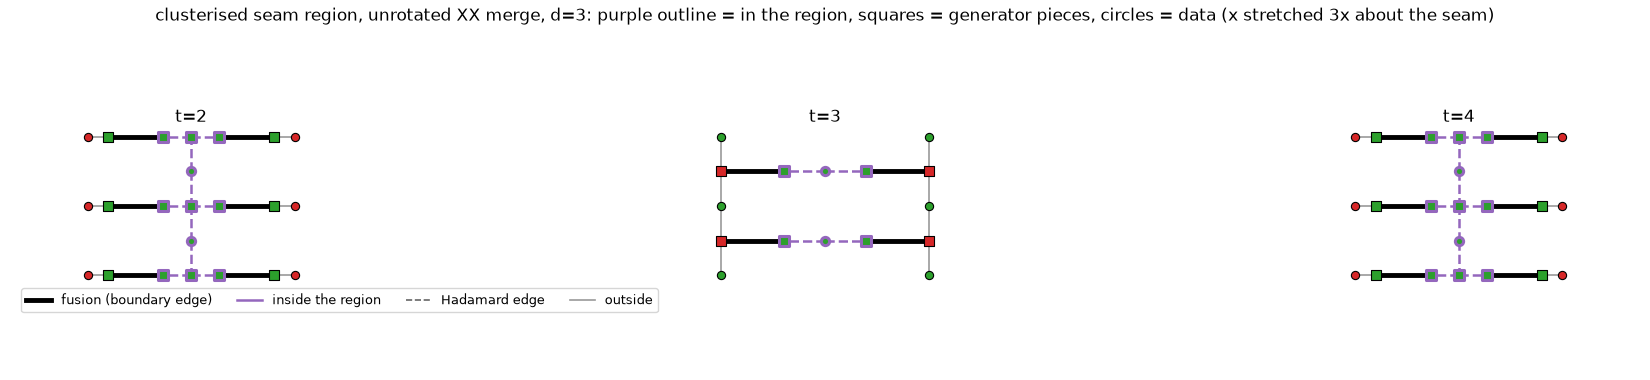

In [26]:
draw_clustered(3, "XX");

### The clusterised SED in 3D

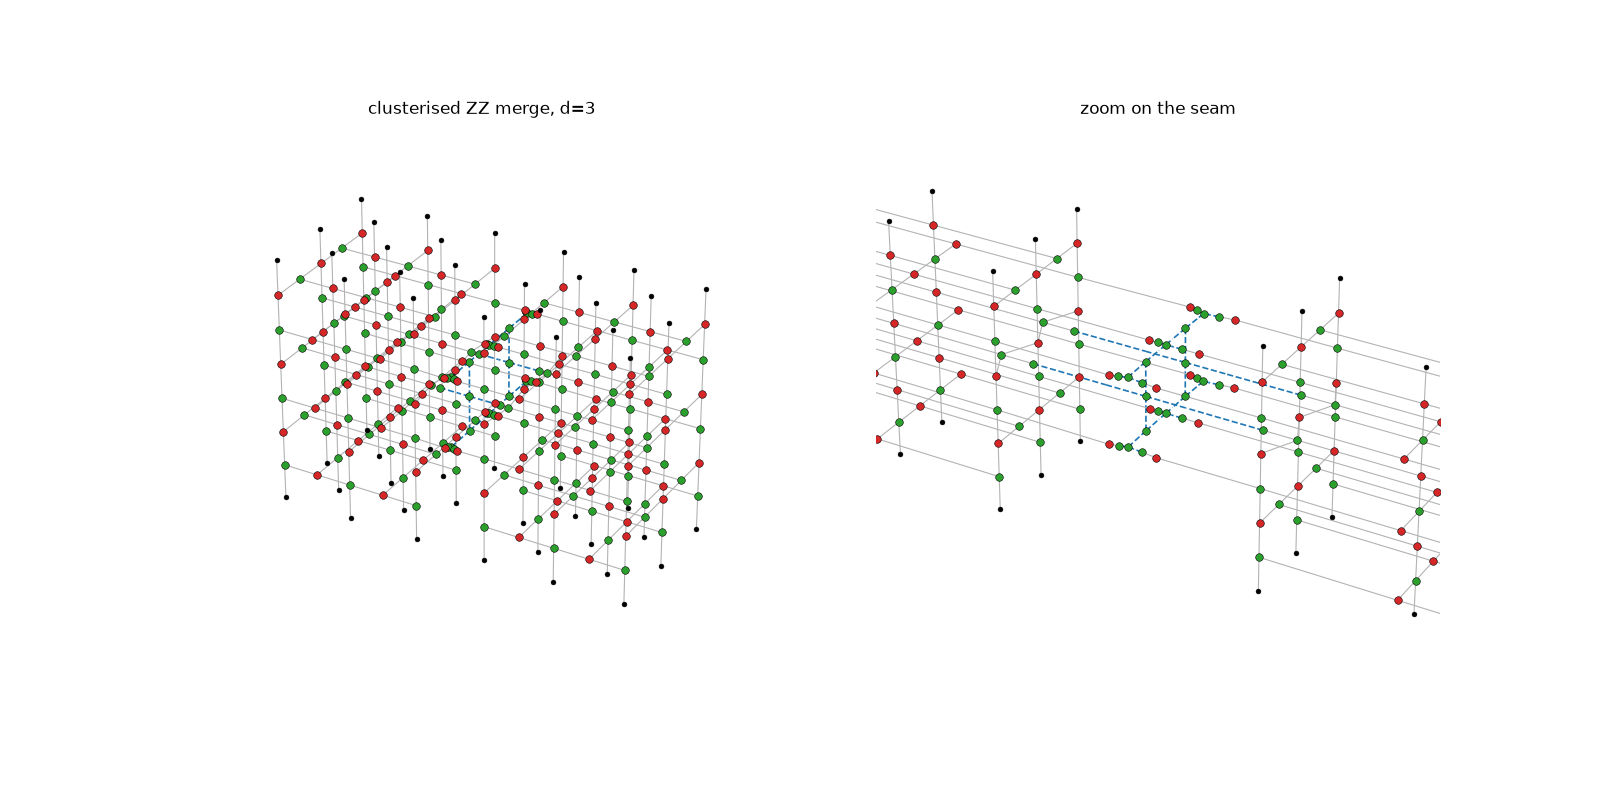

In [27]:
x_seam = s.seam[0][0]
fig = plt.figure(figsize=(16, 8))
hsed.draw(ax=fig.add_subplot(1, 2, 1, projection="3d"), title="clusterised ZZ merge, d=3")
ax = hsed.draw(ax=fig.add_subplot(1, 2, 2, projection="3d"), title="zoom on the seam")
ax.set_xlim(x_seam - 1.5, x_seam + 1.5)
plt.show()

### Checks

The region is graph-like (only Z spiders, joined by Hadamard edges), its
boundary is a matching, every boundary interaction is one of the chosen
fusions, no node gained an outside copy, and the webs and detectors are still
complete. Counts per merge: graph-state qubits, and fusions as `XX`/`ZZ`
(plain edge) or `XZ`/`ZX` (across a Hadamard).

In [28]:
from dizx.realisation import RealisedSED, interactions

print(f"{'joint':<6}{'d':>3}{'cycles':>8}{'qubits':>8}{'XX/ZZ':>7}{'XZ/ZX':>7}{'copies':>8}"
      "  graph-like  matching  =fusions  webs/dets")
for joint in ("ZZ", "XX"):
    for d in (3, 5):
        for n_cycles in (1, 2):
            s, hsed, S, fusions = clusterise(d, joint, n_cycles)
            inside = [v for v in S if hsed.types[v] in SPIDERS]
            graph_like = (all(hsed.types[v] is NodeType.Z for v in inside)
                          and not any(u in S and v in S and hsed.types[u] in SPIDERS
                                      and hsed.types[v] in SPIDERS for u, v, _ in hsed.edges))
            cut = cut_edges(hsed, S)
            ends = [x for u, v, _ in cut for x in (u, v)]
            boundary = [it for it in interactions(hsed, []) if (it.ends[0] in S) != (it.ends[1] in S)]
            copies = sum(1 for v in hsed.types if v[0] == "split" and len(v) == 2)
            kinds = Counter(it.hadamards % 2 for it in boundary)
            print(f"{joint:<6}{d:>3}{n_cycles:>8}{len(inside):>8}{kinds[0]:>7}{kinds[1]:>7}{copies:>8}  "
                  f"{graph_like!s:>10}  {len(ends) == len(set(ends))!s:>8}  "
                  f"{({frozenset(it.ends) for it in boundary} == set(fusions))!s:>8}  "
                  f"{hsed.webs_complete() and hsed.detectors_complete()}")

joint   d  cycles  qubits  XX/ZZ  XZ/ZX  copies  graph-like  matching  =fusions  webs/dets
ZZ      3       1      28     16      0       0        True      True      True  True
ZZ      3       2      45     26      0       0        True      True      True  True
ZZ      5       1      50     28      0       0        True      True      True  True
ZZ      5       2      81     46      0       0        True      True      True  True
XX      3       1      28      0     16       0        True      True      True  True
XX      3       2      45      0     26       0        True      True      True  True
XX      5       1      50      0     28       0        True      True      True  True
XX      5       2      81      0     46       0        True      True      True  True


## A first realisation

`RealisedSED.hybrid` realises the clusterised SED with the chosen fusions. The seam is one
resource state, so every fusion is a boundary fusion (tagged `circuit-graph`);
there are no `graph` fusions for the paper's erasure model to act on until
the region is cut into smaller resource states. Here erasure acts on the
boundary fusions instead. The experiment is deterministic; its graphlike
distance (the probabilities only set edge weights):

In [29]:
from dizx.builders import _finish
from dizx.dem_view import graphlike_distance
from dizx.noise_models import NoiseSpec
from dizx.schedules import UnrotatedSurfaceCodeSchedule

p = 1e-3
NOISE = {
    "boundary erasure": {("circuit-graph", "fusion_measurement"): NoiseSpec("HERALDED_ERASE", 0.1)},
    "circuit": {
        ("circuit", "reset"): NoiseSpec("RESET_FLIP", p),
        ("circuit", "single_qubit_gate"): NoiseSpec("DEPOLARIZE1", p),
        ("circuit", "two_qubit_gate"): NoiseSpec("DEPOLARIZE2", p),
        ("circuit", "single_qubit_measurement"): NoiseSpec("MEASUREMENT_FLIP", p),
        ("circuit-graph", "fusion_gate"): NoiseSpec("DEPOLARIZE2", p),
        ("circuit-graph", "fusion_measurement"): NoiseSpec("MEASUREMENT_FLIP", p),
    },
}
NOISE["erasure+circuit"] = NOISE["boundary erasure"] | NOISE["circuit"]

print(f"{'joint':<6}{'d':>3}{'obs':>5}{'qubits':>8}" + "".join(f"{k:>18}" for k in NOISE))
for joint in ("ZZ", "XX"):
    for d in (3, 5):
        s, hsed, S, fusions = clusterise(d, joint, n_cycles=d)
        real = RealisedSED.hybrid(hsed, S, fusions)
        for obs in ("ZZ", "XX"):
            c = _finish(s, real, obs, UnrotatedSurfaceCodeSchedule()).circuit
            dets, flips = c.compile_detector_sampler().sample(200, separate_observables=True)
            assert not dets.any() and not flips.any()
            print(f"{joint:<6}{d:>3}{obs:>5}{c.num_qubits:>8}"
                  + "".join(f"{graphlike_distance(c, n) or '-':>18}" for n in NOISE.values()))

joint   d  obs  qubits  boundary erasure           circuit   erasure+circuit
ZZ      3   ZZ     122                 4                 3                 3
ZZ      3   XX     122                 3                 3                 3
ZZ      5   ZZ     354                 6                 5                 5
ZZ      5   XX     354                 5                 5                 5
XX      3   ZZ     122                 3                 3                 3
XX      3   XX     122                 4                 3                 3
XX      5   ZZ     354                 5                 5                 5
XX      5   XX     354                 6                 5                 5
